# A2: Handcrafted feature check

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from skimage.color import rgb2hsv


def find_repo_root(start):
    for folder in (start, *start.parents):
        if (folder / "src" / "data.py").is_file():
            return folder
    raise FileNotFoundError(f"No folder containing src/data.py found at or above {start}.")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
sys.path.insert(0, str(REPO_ROOT / "src"))

from data import CLASS_SHORT_NAMES, RESOLUTIONS, load_split
from features import (
    FEATURE_GROUPS,
    LBP_CODES,
    edge_map,
    extract_features,
    feature_names,
    hog_image,
    lbp_codes,
    nucleus_mask,
    to_grayscale,
)

SEED = 1
FIGURES_DIR = REPO_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

## 2. One train image per class

The first train image of each class; the same index is used at every resolution.

In [2]:
train_labels = load_split(28, "train")[1]
sample_indices = [int(np.flatnonzero(train_labels == c)[0]) for c in range(len(CLASS_SHORT_NAMES))]
samples = {res: load_split(res, "train")[0][sample_indices] for res in RESOLUTIONS}

for name, index in zip(CLASS_SHORT_NAMES, sample_indices):
    print(f"{name:<22} train index {index}")

basophil               train index 26
eosinophil             train index 10
erythroblast           train index 6
immature granulocyte   train index 1
lymphocyte             train index 28
monocyte               train index 22
neutrophil             train index 2
platelet               train index 0


## 3. Feature maps

Each panel uses the same processing as `src/features.py`.

In [3]:
def show(ax, data, **kwargs):
    ax.imshow(data, interpolation="nearest", **kwargs)
    ax.set_xticks([])
    ax.set_yticks([])


def show_nucleus(ax, image):
    nucleus = nucleus_mask(image)
    show(ax, nucleus, cmap="gray")
    if nucleus.any():
        ax.contour(nucleus, levels=[0.5], colors="tab:red", linewidths=1)


PANELS = {
    "original": lambda ax, image: show(ax, image),
    "grayscale": lambda ax, image: show(ax, to_grayscale(image), cmap="gray", vmin=0, vmax=1),
    "LBP": lambda ax, image: show(
        ax, lbp_codes(to_grayscale(image)), cmap="viridis", vmin=0, vmax=LBP_CODES - 1
    ),
    "Canny edges": lambda ax, image: show(ax, edge_map(to_grayscale(image)), cmap="gray"),
    "HOG": lambda ax, image: show(ax, hog_image(to_grayscale(image)), cmap="gray"),
    "nucleus mask": show_nucleus,
    "hue": lambda ax, image: show(ax, rgb2hsv(image / 255.0)[..., 0], cmap="twilight", vmin=0, vmax=1),
}

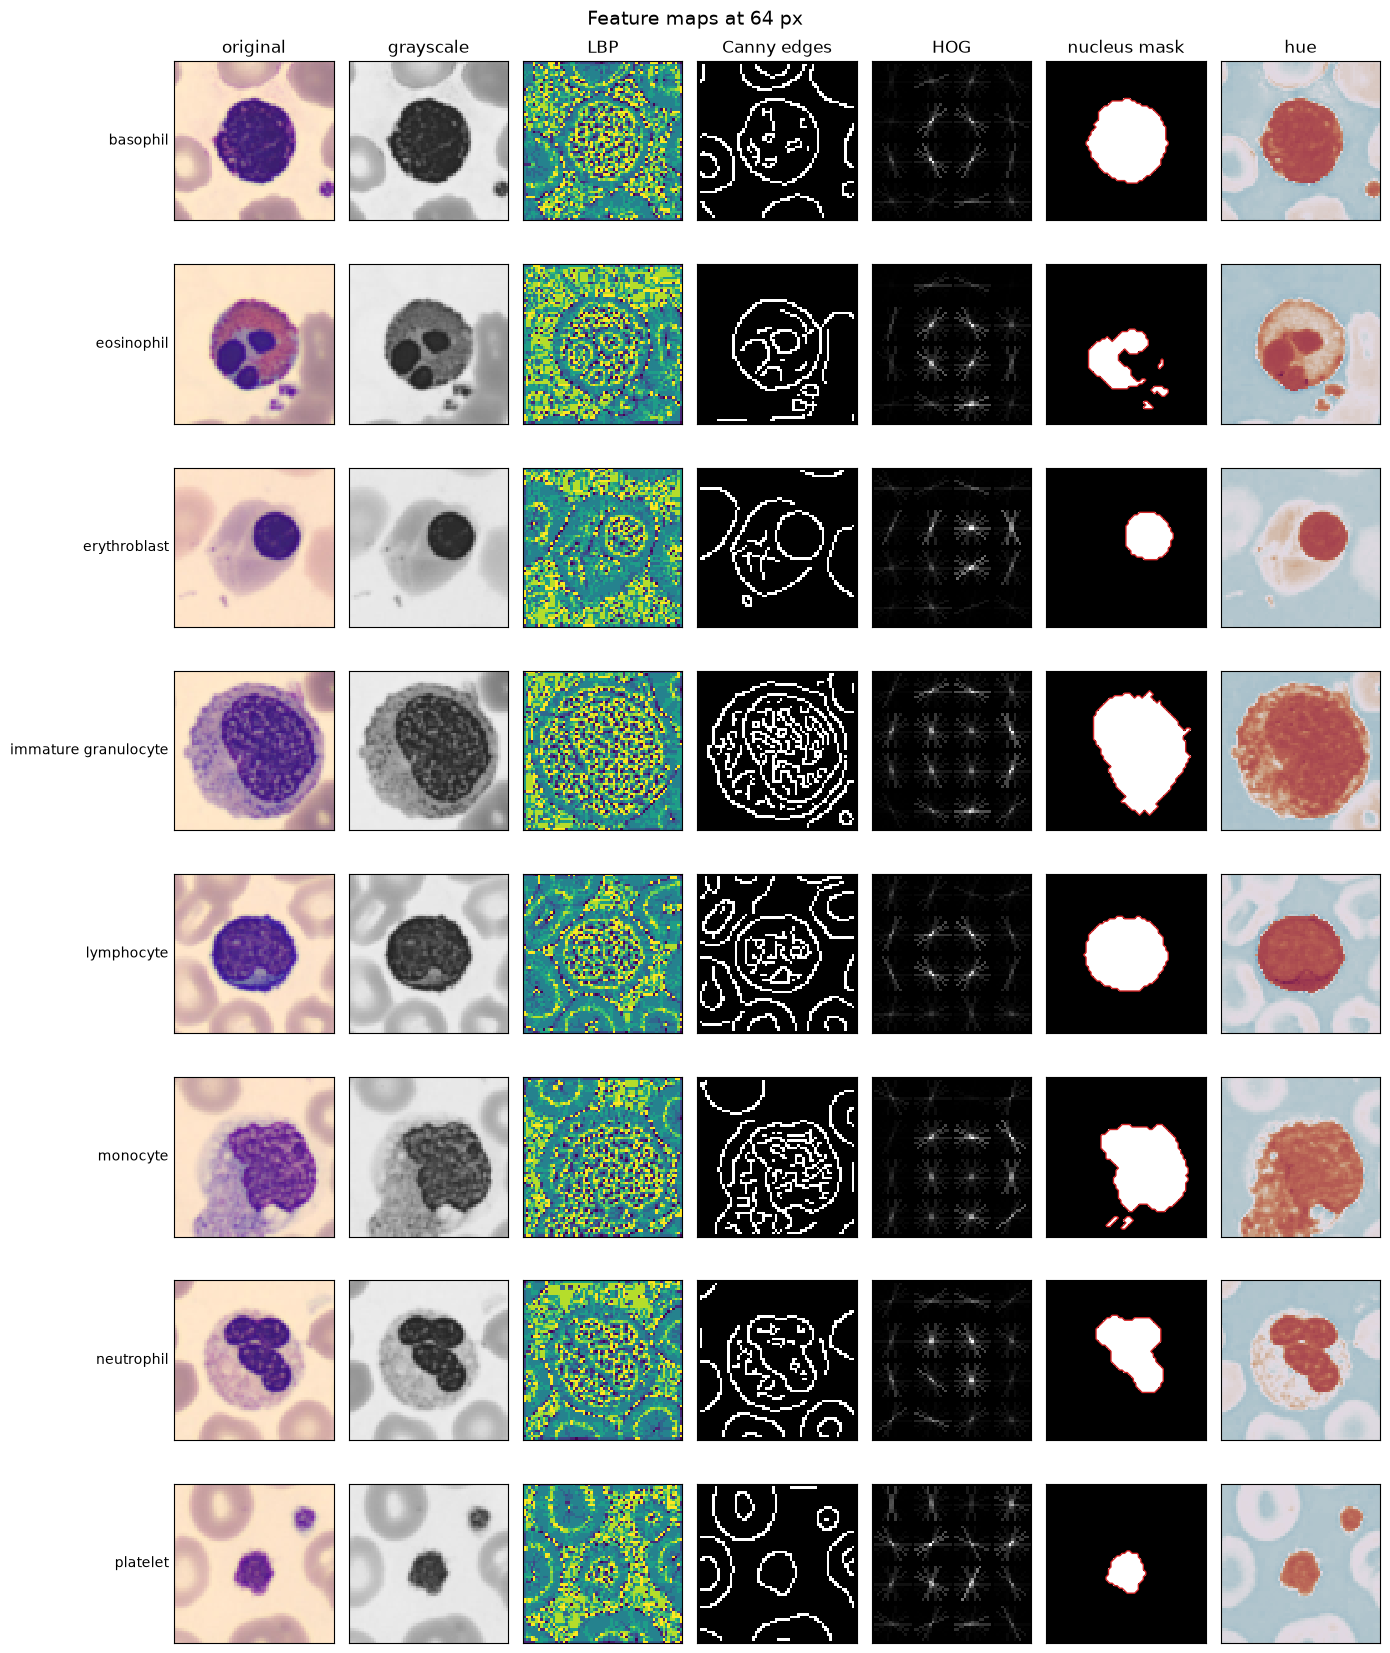

In [4]:
RESOLUTION = 64

fig, axes = plt.subplots(len(CLASS_SHORT_NAMES), len(PANELS), figsize=(14, 17))
for row, (name, image) in enumerate(zip(CLASS_SHORT_NAMES, samples[RESOLUTION])):
    for col, (title, draw) in enumerate(PANELS.items()):
        draw(axes[row, col], image)
        if row == 0:
            axes[row, col].set_title(title)
    axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center")
fig.suptitle(f"Feature maps at {RESOLUTION} px", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "A2_feature_maps.png", dpi=200)
plt.show()

## 4. Resolution comparison

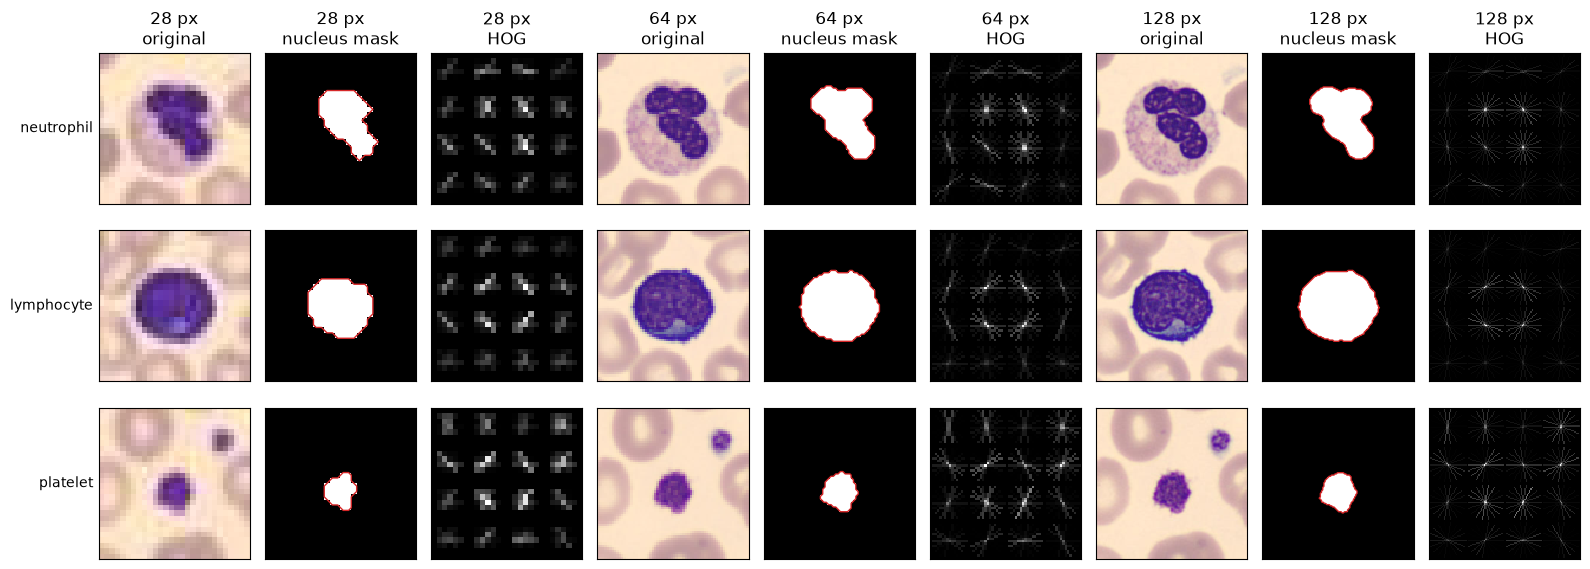

In [5]:
COMPARE_CLASSES = ("neutrophil", "lymphocyte", "platelet")
COMPARE_PANELS = ("original", "nucleus mask", "HOG")

fig, axes = plt.subplots(
    len(COMPARE_CLASSES), len(RESOLUTIONS) * len(COMPARE_PANELS), figsize=(16, 6)
)
for row, name in enumerate(COMPARE_CLASSES):
    class_index = CLASS_SHORT_NAMES.index(name)
    for r, res in enumerate(RESOLUTIONS):
        for p, panel in enumerate(COMPARE_PANELS):
            ax = axes[row, r * len(COMPARE_PANELS) + p]
            PANELS[panel](ax, samples[res][class_index])
            if row == 0:
                ax.set_title(f"{res} px\n{panel}")
    axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "A2_resolution_comparison.png", dpi=200)
plt.show()

## 5. Feature values for one image

In [6]:
names = feature_names()
image = samples[RESOLUTION][CLASS_SHORT_NAMES.index("neutrophil")]
values = dict(zip(names, extract_features(image)))

print(f"neutrophil, {RESOLUTION} px: {len(values)} features, all finite: {np.isfinite(list(values.values())).all()}")
for group in FEATURE_GROUPS:
    print(f"  {group:<8} {sum(name.startswith(f'{group}_') for name in names)}")

neutrophil, 64 px: 379 features, all finite: True
  color    37
  texture  14
  shape    328


In [7]:
SHOWN = (
    "color_rgb_mean_r",
    "color_rgb_mean_g",
    "color_rgb_mean_b",
    "color_hsv_mean_h_sin",
    "color_hsv_mean_h_cos",
    "color_hsv_std_h",
    "texture_glcm_contrast",
    "texture_glcm_homogeneity",
    "texture_glcm_energy",
    "texture_glcm_correlation",
    "shape_edge_density",
    "shape_nucleus_area",
    "shape_nucleus_eccentricity",
    "shape_nucleus_solidity",
)
for name in SHOWN:
    print(f"{name:<28} {values[name]:.4f}")

# Histogram groups are fractions and should each sum to 1.
for prefix in ("color_hist_r_", "color_hist_g_", "color_hist_b_", "texture_lbp_"):
    total = sum(v for name, v in values.items() if name.startswith(prefix))
    print(f"sum of {prefix}*: {total:.4f}")
hog_values = np.array([v for name, v in values.items() if name.startswith("shape_hog_")])
print(f"HOG: {hog_values.size} values in [{hog_values.min():.4f}, {hog_values.max():.4f}]")

color_rgb_mean_r             0.8362
color_rgb_mean_g             0.7085
color_rgb_mean_b             0.7051
color_hsv_mean_h_sin         0.1358
color_hsv_mean_h_cos         0.9907
color_hsv_std_h              0.1096
texture_glcm_contrast        327.8589
texture_glcm_homogeneity     0.3191
texture_glcm_energy          0.1130
texture_glcm_correlation     0.9506
shape_edge_density           0.1292
shape_nucleus_area           0.1318
shape_nucleus_eccentricity   0.7815
shape_nucleus_solidity       0.8970
sum of color_hist_r_*: 1.0000
sum of color_hist_g_*: 1.0000
sum of color_hist_b_*: 1.0000
sum of texture_lbp_*: 1.0000
HOG: 324 values in [0.0017, 0.2801]


## 6. Nucleus mask check

Six random train images per class at 64 px, each next to its nucleus mask from `src/features.py` outlined in red. For checking the mask only, not for the paper.

In [8]:
CHECK_RESOLUTION = 64
CHECK_PER_CLASS = 6

rng = np.random.default_rng(SEED)
check_images = load_split(CHECK_RESOLUTION, "train")[0]
check_indices = [
    np.sort(rng.choice(np.flatnonzero(train_labels == c), CHECK_PER_CLASS, replace=False))
    for c in range(len(CLASS_SHORT_NAMES))
]

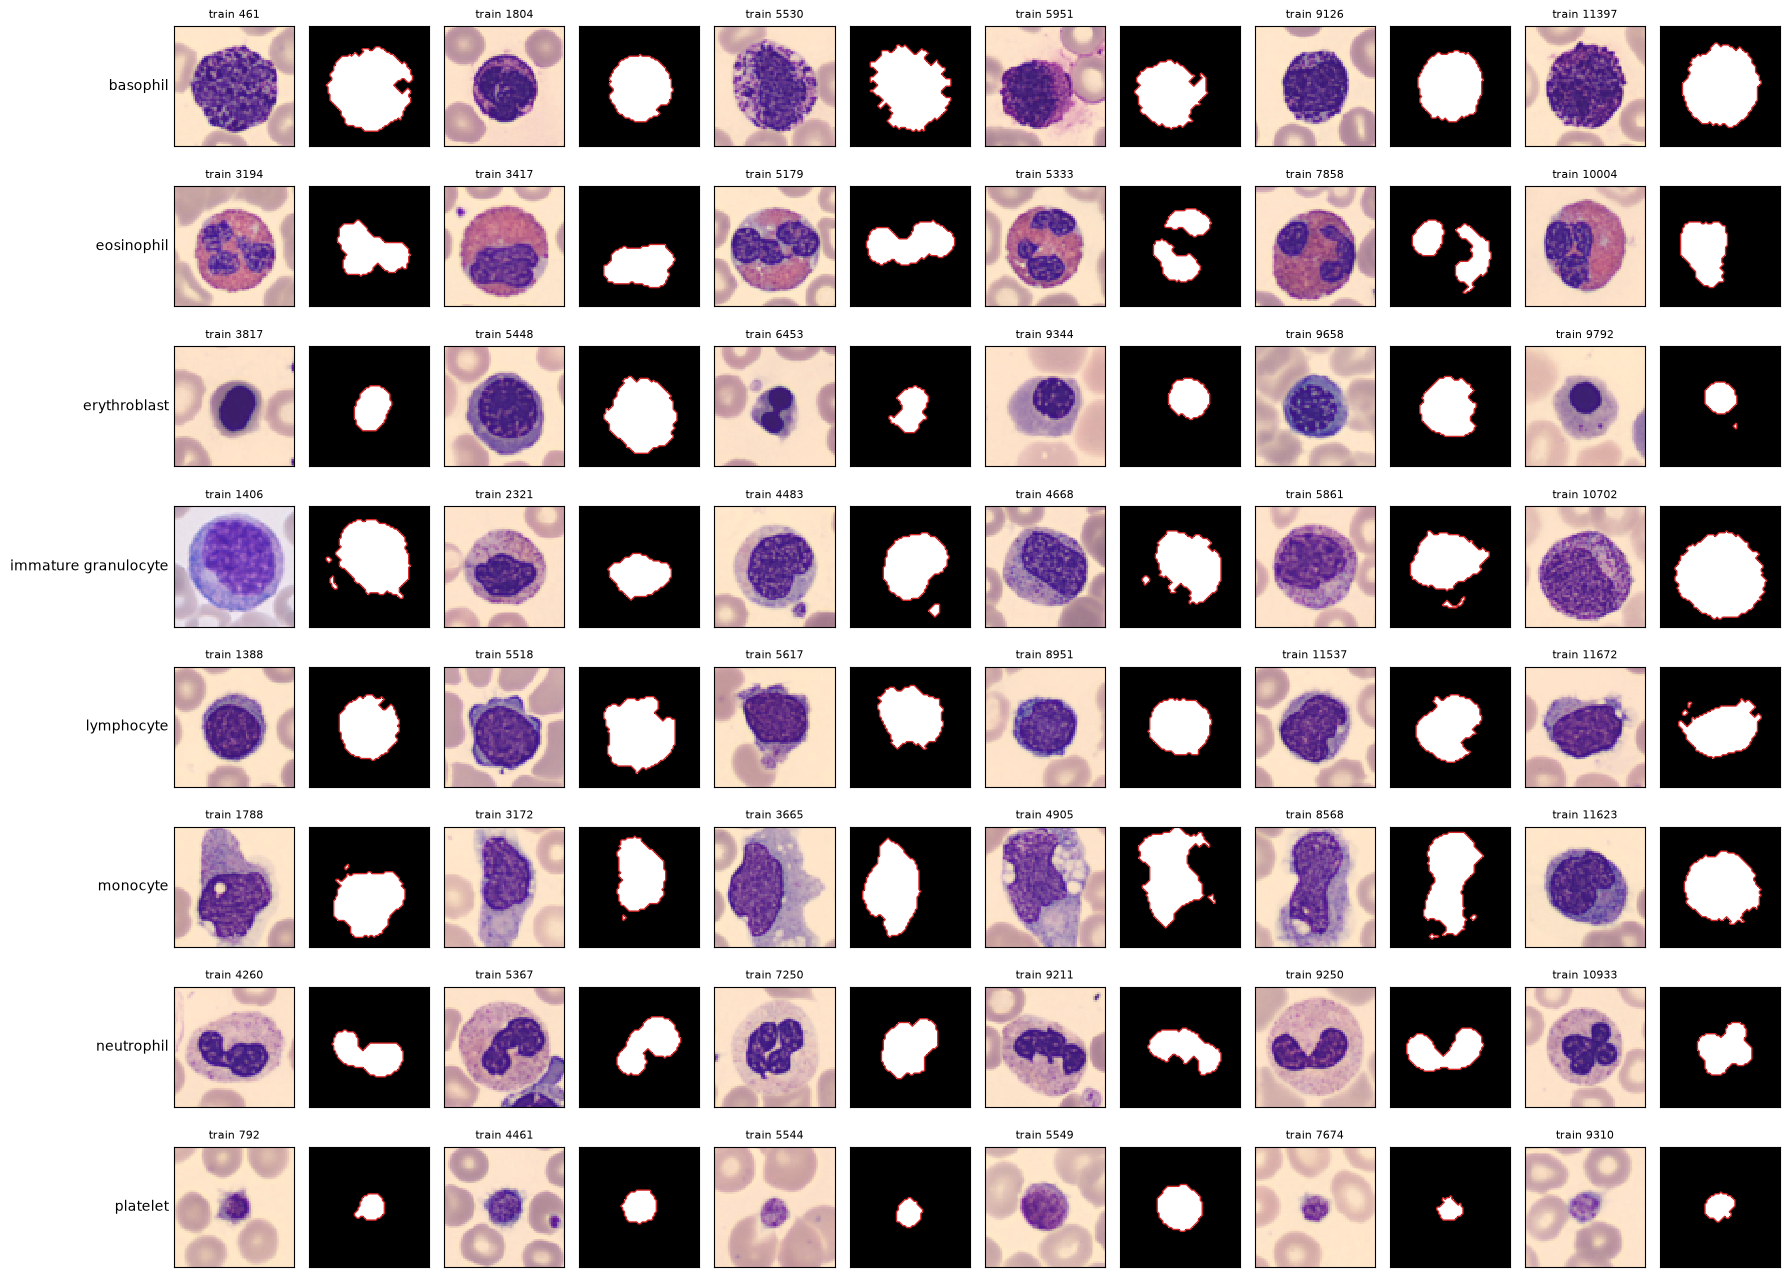

In [9]:
fig, axes = plt.subplots(len(CLASS_SHORT_NAMES), 2 * CHECK_PER_CLASS, figsize=(18, 13))
for row, (name, indices) in enumerate(zip(CLASS_SHORT_NAMES, check_indices)):
    for i, index in enumerate(indices):
        image = check_images[index]
        PANELS["original"](axes[row, 2 * i], image)
        show_nucleus(axes[row, 2 * i + 1], image)
        axes[row, 2 * i].set_title(f"train {index}", fontsize=8)
    axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "A2_nucleus_check.png", dpi=150)
plt.show()